In [1]:
import sys 
import os
from datetime import datetime
today = datetime.now().strftime("%Y-%m-%d")

import anndata as ad
import hdf5plugin
import squidpy as sq
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from spatialdata_io.readers.xenium import xenium_aligned_image
import spatialdata as sd
import rapids_singlecell as rsc

import pertpy
milo = pertpy.tl.Milo()

import warnings
warnings.filterwarnings('ignore', category=ad.ImplicitModificationWarning)

# Add repo path to sys path (allows to access scripts and metadata from repo)
repo_path,_ = os.path.split(os.path.split(os.getcwd())[0])
repo_path = '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses'
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/scripts')
sys.path.insert(3, '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts')

# Autoreload custom scripts
%load_ext autoreload
%autoreload 2

# Define paths
plots_path = f'{repo_path}/plots/'
data_path = f'{repo_path}/data/'
model_path = os.path.join(repo_path, 'models')
general_data_path = '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/data/'

print('Dir for plots: {}'.format(plots_path))
print('Dir for data: {}'.format(data_path))

# Formatting
from matplotlib import font_manager
font_manager.fontManager.addfont("/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf")
plt.style.use('/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts/plotting/thyAgeing.mplstyle')

from plotting.utils import calc_figsize, thyAgeing_greys, thyAgeing_colors

Dir for plots: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/plots/
Dir for data: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/data/


In [2]:
# Load integrated HnE data
he_adata = ad.read_h5ad(f'{data_path}/morphoFM/thyAging_CAM_morphoFM_mpp025_mf2_he_coral.h5ad')

niche_labels = pd.read_excel('/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/data/morpho_niches/morpho_niches.xlsx', index_col=0)[['morpho_niche_l3', 'morpho_niche_l2', 'morpho_niche_l1', 'morpho_niche_keep']].reset_index(names='leiden_r2.0')
niche_labels['leiden_r2.0'] = niche_labels['leiden_r2.0'].astype(str)
he_adata.obs = he_adata.obs.reset_index(names='tile_id').merge(niche_labels, on='leiden_r2.0', how='left').set_index('tile_id')

# Only keep non-artifactual tiles
he_adata = he_adata[he_adata.obs['morpho_niche_keep'], :]

he_adata.obs.head()

,sample,x0,y0,x1,y1,cx_img,cy_img,tile_size,stride,tissue_fraction,...,tissue_embedding,has_xenium,source,leiden_r1.0,leiden_r0.5,leiden_r2.0,morpho_niche_l3,morpho_niche_l2,morpho_niche_l1,morpho_niche_keep
tile_id,,,,,,,,,,,,,,,,,,,,,
A70-THY-0-FFPE-1_tile_00000000,A70-THY-0-FFPE-1,26208,1792,26432,2016,26320.0,1904.0,224,224,0.242128,...,FFPE,False,CAM,4,10,29,fibrosis_adipose,fibrosis_adipose,fibrosis_adipose,True
A70-THY-0-FFPE-1_tile_00000001,A70-THY-0-FFPE-1,26432,1792,26656,2016,26544.0,1904.0,224,224,0.549685,...,FFPE,False,CAM,12,4,17,fibrosis_adipose,fibrosis_adipose,fibrosis_adipose,True
A70-THY-0-FFPE-1_tile_00000002,A70-THY-0-FFPE-1,26656,1792,26880,2016,26768.0,1904.0,224,224,0.416354,...,FFPE,False,CAM,15,1,6,fibrosis,fibrosis,fibrosis,True
A70-THY-0-FFPE-1_tile_00000003,A70-THY-0-FFPE-1,26880,1792,27104,2016,26992.0,1904.0,224,224,0.915537,...,FFPE,False,CAM,0,1,6,fibrosis,fibrosis,fibrosis,True
A70-THY-0-FFPE-1_tile_00000004,A70-THY-0-FFPE-1,27104,1792,27328,2016,27216.0,1904.0,224,224,0.570532,...,FFPE,False,CAM,12,2,25,fibrosis_adipose,fibrosis_adipose,fibrosis_adipose,True


## Milo

n neighbourhoods: 26276  |  mean size: 109.7  |  median: 80


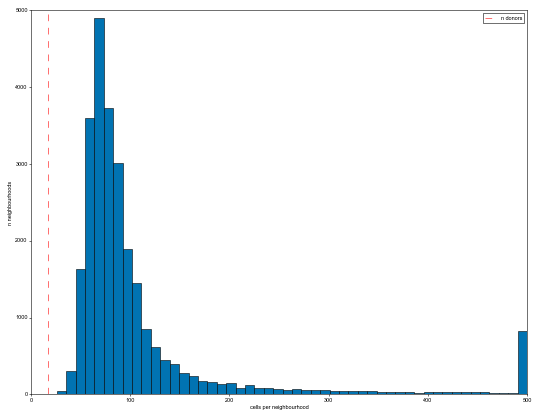

In [44]:
# Construct nhoods
mdata = milo.load(he_adata)

# CORAL integrates platform globally but NOT locally: a plain KNN on X_pca_coral gave ~11% Xenium-
# pure neighbourhoods (vs ~0 expected under random mixing), i.e. tiles still nearest-neighbour by
# platform. So use bbknn, which forces cross-platform edges (neighbors_within_batch connects each
# cell into BOTH batches) and yields platform-mixed neighbourhoods -- the recommended Milo graph for
# batchy data. With 2 batches, effective k = neighbors_within_batch * 2, so 25 -> ~50 neighbours,
# giving neighbourhoods large enough for stable donor-level counts (avoids the k~6 separation).
sc.external.pp.bbknn(mdata["rna"], batch_key='has_xenium', use_rep='X_pca_coral',
                     neighbors_within_batch=25, n_pcs=50, use_annoy=False)  # pyNNDescent
milo.make_nhoods(mdata["rna"], prop=0.1)

# QC: neighbourhood size distribution should sit well right of the donor count
nhood_sizes = np.asarray(mdata["rna"].obsm["nhoods"].sum(0)).ravel()
print(f"n neighbourhoods: {len(nhood_sizes)}  |  mean size: {nhood_sizes.mean():.1f}  |  median: {np.median(nhood_sizes):.0f}")
plt.hist(nhood_sizes, bins=50)
plt.xlabel("cells per neighbourhood"); plt.ylabel("n neighbourhoods")
plt.axvline(17, color='r', ls='--', label='n donors'); plt.legend(); plt.show()

# Count nhoods.
# Aggregate at DonorID (not slide): pools each donor's multiple slides into one sample, so the
# replication unit is the donor and multi-slide pseudoreplication is removed. has_xenium varies
# WITHIN some donors so it can't be a donor-level covariate (see design below).
mdata = milo.count_nhoods(mdata, sample_col="DonorID")

In [45]:
for anno in ['morpho_niche_l3', 'morpho_niche_l2', 'morpho_niche_l1']:
    milo.annotate_nhoods(mdata, anno_col = anno)
    mdata['milo'].var.rename(columns = {'nhood_annotation' : f'nhood_{anno}',
                                        'nhood_annotation_frac' : f'nhood_{anno}_frac'}, inplace = True)
    
mdata['milo'].var.head()

,index_cell,kth_distance,nhood_morpho_niche_l3,nhood_morpho_niche_l3_frac,nhood_morpho_niche_l2,nhood_morpho_niche_l2_frac,nhood_morpho_niche_l1,nhood_morpho_niche_l1_frac
0,A70-THY-0-FFPE-1_tile_00000009,0.490756,endothelium_vessel,0.516667,vessel,0.866667,vessel,0.866667
1,A70-THY-0-FFPE-1_tile_00000015,0.452427,fibrosis_interstitial,0.492958,fibrosis,0.492958,fibrosis,0.492958
2,A70-THY-0-FFPE-1_tile_00000034,0.485088,fibrosis_interstitial,0.881356,fibrosis,0.898305,fibrosis,0.898305
3,A70-THY-0-FFPE-1_tile_00000060,0.419372,endothelium_vessel,0.958904,vessel,1.000000,vessel,1.000000
4,A70-THY-0-FFPE-1_tile_00000078,0.427013,adipose,0.981132,adipose,0.981132,adipose,0.981132


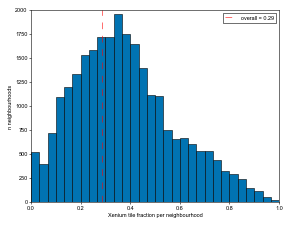

0.9% of neighbourhoods are Xenium-free; 0.0% are Xenium-pure


In [46]:
# --- QC: neighbourhood platform mixing ---
# Platform mixing is enforced by the bbknn graph (CORAL alone leaves residual local platform
# structure). Check it worked: neighbourhoods should NOT be Xenium-pure, and their Xenium fractions
# should scatter around the overall baseline rather than pile up at 0/1. At size ~50 and 29% overall
# Xenium, random mixing implies ~0% pure nhoods, so even a few % pure signals residual structure.
N = mdata["rna"].obsm["nhoods"]                                        # tiles x nhoods (sparse)
xen = (mdata["rna"].obs["has_xenium"].astype(str) == "True").values.astype(float)
nhood_xen_frac = np.asarray(N.T @ xen).ravel() / np.asarray(N.sum(0)).ravel()
baseline = xen.mean()

fig, ax = plt.subplots(figsize=(4, 3))
ax.hist(nhood_xen_frac, bins=30)
ax.axvline(baseline, color='r', ls='--', label=f'overall = {baseline:.2f}')
ax.set_xlabel('Xenium tile fraction per neighbourhood')
ax.set_ylabel('n neighbourhoods')
ax.legend()
plt.show()

print(f'{(nhood_xen_frac == 0).mean():.1%} of neighbourhoods are Xenium-free; '
      f'{(nhood_xen_frac == 1).mean():.1%} are Xenium-pure')

Only 20% of slides are Xenium, so some Xenium-free nhoods are expected -> good to go

In [47]:
# --- Donor-level design setup ---
obs = mdata["rna"].obs

# Use each donor's Xenium tile fraction as a continuous platform-composition nuisance covariate to deal with dual-platform donors. 
# It correlates with age but varies within every age group, so the design stays full rank.
obs["da_xenium_frac"] = (
    obs.groupby("DonorID", observed=True)["has_xenium"]
       .transform(lambda x: (x.astype(str) == "True").mean())
       .astype(float)
)

# Age group: reorder categories
obs["da_age_group"] = obs["age_group"].astype("category").cat.reorder_categories(['infant', 'paed', 'adult'])

comparisons = [('adult', 'paed'), ('paed', 'infant'), ('adult', 'infant'),]
milo_dict = {}
for c in comparisons:
    # NB: pertpy's pydeseq2 solver treats the LAST design term as the contrast factor
    # (factor_name = design.split("+")[-1]), so da_age_group must come last.
    contrast = f'da_age_group{c[0]}-da_age_group{c[1]}'
    milo.da_nhoods(mdata, design="~sex+da_xenium_frac+da_age_group", model_contrasts=contrast)

    milo_dict[f'{c[0]}_vs_{c[1]}'] = mdata['milo'].var.copy()

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.02 seconds.

Fitting dispersions...
... done in 12.22 seconds.

Fitting dispersion trend curve...
... done in 0.48 seconds.

Fitting MAP dispersions...
... done in 11.09 seconds.

Fitting LFCs...
... done in 39.98 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 2.65 seconds.



Log2 fold change & Wald test p-value: da_age_group adult vs paed
       baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
0      1.280884        1.955250  2.639413  0.740790  0.458821  0.564652
1      1.714769        3.293494  2.254479  1.460867  0.144052  0.457006
2      1.383407        2.164062  2.357026  0.918132  0.358550  0.511914
3      1.415826        2.152157  2.855942  0.753572  0.451107  0.559772
4      1.127605        1.043362  2.341964  0.445507  0.655953  0.684542
...         ...             ...       ...       ...       ...       ...
26271  4.281498       -4.342628  1.686449 -2.575013  0.010024  0.272715
26272  6.184064       -3.885876  2.070341 -1.876926  0.060528  0.457006
26273  4.540285       -2.858357  2.220794 -1.287088  0.198064  0.458520
26274  2.637633       -1.238788  2.625200 -0.471883  0.637010  0.668630
26275  3.902909       -4.117157  1.920224 -2.144103  0.032025  0.457006

[26276 rows x 6 columns]
Using None as control genes, passed at DeseqD

Fitting size factors...
... done in 0.02 seconds.

Fitting dispersions...
... done in 12.17 seconds.

Fitting dispersion trend curve...
... done in 0.49 seconds.

Fitting MAP dispersions...
... done in 11.02 seconds.

Fitting LFCs...
... done in 39.57 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 3.41 seconds.



Log2 fold change & Wald test p-value: da_age_group paed vs infant
       baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
0      1.280884        1.985425  2.852532  0.696022  0.486415  0.927624
1      1.714769        1.805311  2.674696  0.674959  0.499702  0.927624
2      1.383407        2.885870  2.719715  1.061093  0.288648  0.927624
3      1.415826        1.456063  3.061918  0.475539  0.634403  0.927624
4      1.127605        3.695770  2.741412  1.348126  0.177618  0.927624
...         ...             ...       ...       ...       ...       ...
26271  4.281498        1.036299  1.915636  0.540968  0.588529  0.927624
26272  6.184064        0.161972  2.419426  0.066946  0.946624  0.983375
26273  4.540285       -3.444091  2.509625 -1.372353  0.169954  0.927624
26274  2.637633       -4.973285  2.907817 -1.710316  0.087208  0.927624
26275  3.902909       -0.919915  2.216133 -0.415099  0.678069  0.927624

[26276 rows x 6 columns]
Using None as control genes, passed at Deseq

Fitting size factors...
... done in 0.02 seconds.

Fitting dispersions...
... done in 11.57 seconds.

Fitting dispersion trend curve...
... done in 0.46 seconds.

Fitting MAP dispersions...
... done in 10.80 seconds.

Fitting LFCs...
... done in 39.07 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: da_age_group adult vs infant
       baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
0      1.280884        3.940675  2.616812  1.505907  0.132091       NaN
1      1.714769        5.098805  1.966532  2.592790  0.009520       NaN
2      1.383407        5.049932  2.226132  2.268478  0.023300       NaN
3      1.415826        3.608220  2.759043  1.307779  0.190948       NaN
4      1.127605        4.739132  2.400447  1.974271  0.048351       NaN
...         ...             ...       ...       ...       ...       ...
26271  4.281498       -3.306329  1.743208 -1.896692  0.057869  0.098971
26272  6.184064       -3.723904  2.142903 -1.737785  0.082249  0.126209
26273  4.540285       -6.302448  2.188502 -2.879800  0.003979  0.025102
26274  2.637633       -6.212073  2.239724 -2.773589  0.005544  0.029500
26275  3.902909       -5.037073  2.046911 -2.460817  0.013862  0.044417

[26276 rows x 6 columns]


... done in 2.64 seconds.



In [48]:
milo_df = pd.concat(milo_dict, axis=0).reset_index(names=['comparison','nhood_id'])
milo_df.sort_values(by = 'SpatialFDR')

,comparison,nhood_id,index_cell,kth_distance,nhood_morpho_niche_l3,nhood_morpho_niche_l3_frac,nhood_morpho_niche_l2,nhood_morpho_niche_l2_frac,nhood_morpho_niche_l1,nhood_morpho_niche_l1_frac,logCPM,logFC,PValue,FDR,SpatialFDR
43602,paed_vs_infant,17326,A70-THY-0-FFPE-2_tile_00001334,0.413205,medulla_residual,0.934211,medulla,0.960526,medulla,0.960526,1.106036,-43.280851,0.000000e+00,0.000000e+00,0.000000e+00
43685,paed_vs_infant,17409,A70-THY-0-FFPE-2_tile_00002309,0.498111,medulla_residual,0.777778,medulla,0.888889,medulla,0.952381,2.196648,-43.280851,0.000000e+00,0.000000e+00,0.000000e+00
34241,paed_vs_infant,7965,A74-THY-0-FFPE-1_tile_00005516,0.439857,medulla_residual,0.865385,medulla,1.000000,medulla,1.000000,2.230875,-31.235023,2.148394e-15,1.767197e-11,1.889554e-11
57807,adult_vs_infant,5255,A72.ome_tile_00001993,0.375226,endothelium_edge,0.314000,vessel,0.432000,vessel,0.432000,19.086912,7.519051,7.384577e-11,1.296436e-06,1.633104e-06
65041,adult_vs_infant,12489,A45.ome_tile_00003468,0.382930,endothelium_edge,0.336000,vessel,0.358000,vessel,0.358000,22.654620,8.908398,6.923111e-09,1.736316e-05,2.155857e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78768,adult_vs_infant,26216,A66-THY-0-FFPE-2_tile_00015815,0.472005,fibrosis,0.487500,fibrosis,0.575000,fibrosis,0.575000,3.019512,4.619896,NaN,NaN,1.000000e+00
66,adult_vs_paed,66,A70-THY-0-FFPE-1_tile_00001034,0.486457,endothelium,0.991525,vessel,0.991525,vessel,0.991525,3.640546,3.196358,NaN,NaN,1.000000e+00
78802,adult_vs_infant,26250,A66-THY-0-FFPE-2_tile_00016237,0.409205,adipose_edge,0.494949,adipose,0.494949,adipose,0.494949,3.892612,5.827423,NaN,NaN,1.000000e+00
2986,adult_vs_paed,2986,A66-THY-0-FFPE-1_tile_00000503,0.359654,medulla,0.975000,medulla,0.975000,medulla,0.975000,4.432138,4.151651,NaN,NaN,1.000000e+00


In [49]:
# --- Guard: flag probable quasi-separation neighbourhoods ---
# Tiny/zero-count neighbourhoods make the NB-GLM coefficient run off to +/-inf, producing huge
# |logFC| with a hard-0 p-value. Those are numerical artifacts, NOT real enrichment. A healthy
# run should have |logFC| roughly within +/-10; anything beyond that (especially if it passes
# SpatialFDR) is a red flag that neighbourhoods are still too sparse -> raise n_neighbors.
LOGFC_LIMIT = 10.0
SPATIALFDR_ALPHA = 0.1

extreme = milo_df[milo_df['logFC'].abs() > LOGFC_LIMIT]
extreme_sig = extreme[extreme['SpatialFDR'] < SPATIALFDR_ALPHA]
n_sig = (milo_df['SpatialFDR'] < SPATIALFDR_ALPHA).sum()

print(f"logFC range: [{milo_df['logFC'].min():.1f}, {milo_df['logFC'].max():.1f}]")
print(f"|logFC| > {LOGFC_LIMIT}: {len(extreme)} / {len(milo_df)} neighbourhoods "
      f"({len(extreme) / len(milo_df):.1%})")
print(f"SpatialFDR < {SPATIALFDR_ALPHA}: {n_sig} significant; "
      f"of these {len(extreme_sig)} have |logFC| > {LOGFC_LIMIT} (probable separation artifacts)")

if len(extreme_sig):
    print("\n!! WARNING: significant hits are driven by quasi-separation. "
          "Do NOT trust these -- increase n_neighbors and rerun.")
    display(extreme_sig.sort_values('logFC')[
        ['comparison', 'nhood_id', 'nhood_morpho_niche_l1', 'logFC', 'PValue', 'SpatialFDR']].head(20))
else:
    print("\nOK: no significant neighbourhood exceeds the |logFC| limit -- results look numerically stable.")

logFC range: [-43.3, 79.8]
|logFC| > 10.0: 735 / 78828 neighbourhoods (0.9%)
SpatialFDR < 0.1: 10504 significant; of these 4 have |logFC| > 10.0 (probable separation artifacts)

!! WARNING: significant hits are driven by quasi-separation. Do NOT trust these -- increase n_neighbors and rerun.


,comparison,nhood_id,nhood_morpho_niche_l1,logFC,PValue,SpatialFDR
43602,paed_vs_infant,17326,medulla,-43.280851,0.000000e+00,0.000000e+00
43685,paed_vs_infant,17409,medulla,-43.280851,0.000000e+00,0.000000e+00
34241,paed_vs_infant,7965,medulla,-31.235023,2.148394e-15,1.889554e-11
58418,adult_vs_infant,5866,medulla,10.324930,3.195698e-04,7.121737e-03


In [ ]:
sig = milo_df[milo_df['SpatialFDR'] < 0.1]
print(sig.groupby('comparison')['logFC'].apply(lambda x: (x > 0).mean()))

comparison
adult_vs_infant    0.950386
paed_vs_infant     0.000000
Name: logFC, dtype: float64


In [52]:
# Interim RELATIVE view of the Milo results. Milo's raw logFC carries a global compositional offset
# (under strong involution all niches read ~+5, incl. cortex/medulla which must fall). Re-centering
# per comparison to the median neighbourhood removes that offset, so logFC_centered reads as
# enrichment/depletion RELATIVE to the overall tissue shift. This is a pragmatic reference choice;
# for rigorous directional claims use the scCODA section below.
milo_df['logFC_centered'] = milo_df.groupby('comparison')['logFC'].transform(lambda x: x - x.median())

# Sanity: after centering, cortex should go negative (relatively depleted) and adipose/fibrosis positive
(milo_df[milo_df['SpatialFDR'] < 0.1]
 .groupby(['comparison', 'nhood_morpho_niche_l1'])['logFC_centered']
 .median().unstack().round(2))

nhood_morpho_niche_l1,adipose,adipose_fibrosis,cortex,fibrosis,medulla,vessel
comparison,,,,,,
adult_vs_infant,1.0,0.7,0.08,0.89,0.77,0.97
paed_vs_infant,NaN,NaN,NaN,NaN,-44.59,NaN


In [33]:
milo_df.to_csv(f'{data_path}/morphoFM/morphoNiches_milo_DA_results_{today}.csv', index=False)

In [34]:
col_niche = 'morpho_niche_l3'
col_niche_levels = ['cortex', 'cortex_edge', 'capsule_interstitial','cortex_medulla_residual',
                    'medulla', 'medulla_hc', 'medulla_residual', 
                    'adipose', 'adipose_fibrosis', 'adipose_edge',
                    'fibrosis_interstitial', 'fibrosis',
                    'endothelium', 'endothelium_vessel', 'endothelium_edge',]
# col_niche_levels = ['cortex', 'medulla', 'medulla_hc', 'adipose', 'adipose_fibrosis', 'fibrosis', 'vessel',]

df = milo_df.copy()
df[f'nhood_{col_niche}'] = pd.Categorical(df[f'nhood_{col_niche}'], categories=col_niche_levels, ordered=True)
df['is_sig'] = df['SpatialFDR'] < 0.05

df.head()

,comparison,nhood_id,index_cell,kth_distance,nhood_morpho_niche_l3,nhood_morpho_niche_l3_frac,nhood_morpho_niche_l2,nhood_morpho_niche_l2_frac,nhood_morpho_niche_l1,nhood_morpho_niche_l1_frac,logCPM,logFC,PValue,FDR,SpatialFDR,is_sig
0,adult_vs_paed,0,A70-THY-0-FFPE-1_tile_00000009,0.461811,endothelium,0.500000,vessel,1.000000,vessel,1.000000,0.310354,1.527687,0.699411,0.997083,0.995655,False
1,adult_vs_paed,1,A70-THY-0-FFPE-1_tile_00000026,0.414361,adipose_fibrosis,1.000000,adipose_fibrosis,1.000000,adipose_fibrosis,1.000000,0.199195,0.881587,0.842008,0.997083,0.995655,False
2,adult_vs_paed,2,A70-THY-0-FFPE-1_tile_00000064,0.439310,fibrosis_interstitial,0.750000,fibrosis,0.750000,fibrosis,0.750000,0.132797,0.637024,0.885076,0.997083,0.995655,False
3,adult_vs_paed,3,A70-THY-0-FFPE-1_tile_00000067,0.393920,adipose,1.000000,adipose,1.000000,adipose,1.000000,0.462441,1.595704,0.721933,0.997083,0.995655,False
4,adult_vs_paed,4,A70-THY-0-FFPE-1_tile_00000080,0.415076,fibrosis_interstitial,0.636364,fibrosis,0.636364,fibrosis,0.636364,0.469252,0.662422,0.866908,0.997083,0.995655,False


/tmp/ipykernel_1930456/548553950.py:59: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


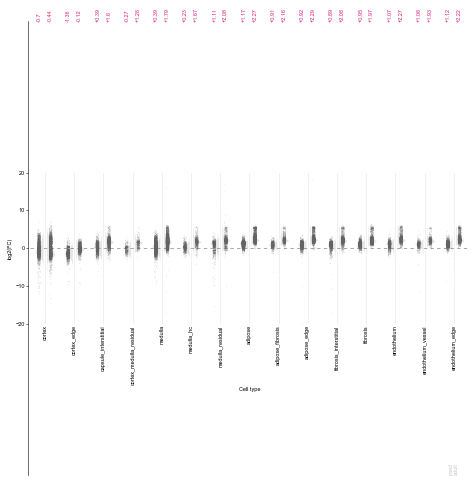

In [37]:
from plotting.utils import thyAgeing_greys,thyAgeing_colors

# Milo beeswarm (landscape)

groups_of_interest = ['paed_vs_infant', 'adult_vs_infant']
group_labels = ['paed', 'adult']

# Calculate median logFC for each nhood_annotation and comparison
df_median = df.groupby(['comparison', f'nhood_{col_niche}'])['logFC'].median().round(decimals=2).reset_index()
df_median = df_median.loc[df_median['comparison'].isin(groups_of_interest)]
df_median['logFC'] = df_median['logFC'].apply(lambda x: f"+{x}" if x >= 0 else str(x))

args = {'x': f'nhood_{col_niche}', 'y': 'logFC', 'hue': 'comparison', 'hue_order': groups_of_interest}
    
plt.figure(figsize=calc_figsize(height=60, width=180))
ax = sns.violinplot(**args, data=df,
                    bw_adjust=.8, cut=0, split=True, density_norm='width',
                    gap=0.3,
                    palette=[thyAgeing_greys['grey2'], thyAgeing_greys['grey2']],
                    edgecolor='black', linewidth=0, inner=None,
                    )
# Get the legend from just the box plot
handles, labels = ax.get_legend_handles_labels()

for violin in ax.collections:
    violin.set_alpha(0.5)
sns.stripplot(**args, data=df.loc[df['is_sig'] == False],
              palette=[thyAgeing_greys['grey4'], thyAgeing_greys['grey4']],
              dodge=True, size=0.5, alpha=0.5, ax=ax)
sns.stripplot(**args, data=df.loc[df['is_sig'] == True],
              palette=[thyAgeing_colors['magenta'], thyAgeing_colors['magenta']],
              dodge=True, size=0.5, alpha=0.5, ax=ax)

plt.ylabel('log2(FC)')
plt.xlabel('Cell type')

# Remove the old legend
ax.get_legend().remove()

plt.text(x=ax.get_xaxis().get_ticklabels()[-1].get_text(), y = ax.get_ylim()[0] + 0.2, s=group_labels[0], ha='right', va='bottom', fontsize=5, color=thyAgeing_greys['grey2'], rotation=90)
plt.text(x=ax.get_xaxis().get_ticklabels()[-1].get_text(), y = ax.get_ylim()[0] + 0.2, s=group_labels[1], ha='left', va='bottom', fontsize=5, color=thyAgeing_greys['grey2'], rotation=90)

ax_labels = [c.get_text() for c in ax.get_xticklabels()]
for i, row in df_median.iterrows():
    tick_pos = ax_labels.index(row[f'nhood_{col_niche}'])
    if row[args['hue']] == args['hue_order'][0]:
        plt.text(y=ax.get_ylim()[1] + 0.2, x=ax.get_xticks()[tick_pos] - 0.1, s=row['logFC'], ha = 'right', fontsize=5, color=thyAgeing_colors['magenta'], rotation=90)
    else:
        plt.text(y=ax.get_ylim()[1] + 0.2, x=ax.get_xticks()[tick_pos] + 0.1, s=row['logFC'], ha = 'left', fontsize=5, color=thyAgeing_colors['magenta'], rotation=90)

# Style axes
sns.despine(bottom=True, trim=True, offset=2)
plt.axhline(0, color=thyAgeing_greys['grey4'], linestyle=(0, (3, 3)), linewidth=0.5)
ax.set_yticks([-20, -10, 0, 10, 20])
ax.set_ylim(-20, 20)
ax.xaxis.grid(True, linestyle='solid', color=thyAgeing_greys['grey2'], alpha=0.5, linewidth=0.5)
ax.tick_params(axis='x', length=0, rotation=90)

plt.tight_layout()
plt.show()
#plt.savefig(f'{plots_path}/freqAnalysis/thyAgeing_all_taa_l2_v2_logFcCellTypes_adult_infant_pub.pdf')

## Compositional niche analysis (scCODA)

Milo tests *relative* abundance; under the extreme compositional change of thymic involution its
per-niche direction is dominated by a global offset (all niches read ~+5 logFC, incl. cortex/medulla,
which must fall). **scCODA** models the niche **proportions** per donor with an explicit reference
niche, so directional calls are compositionally coherent (sum-to-zero: if one niche goes up, another
goes down).

- replication unit: `DonorID` (tiles aggregated to a donor x niche count table)
- covariate of interest: `da_age_group`, reference = `infant` (so effects read as paed-vs-infant and adult-vs-infant)
- reference niche: chosen automatically (a niche present across donors with low dispersion)

In [3]:
from pertpy.tools import Sccoda
sccoda = Sccoda()

# Construct nhoods
mdata = milo.load(he_adata)

# Age as categorical with infant as the reference level
mdata["rna"].obs["da_age_group"] = (
    mdata["rna"].obs["age_group"].astype("category").cat.reorder_categories(['infant', 'paed', 'adult'])
)

# Aggregate tiles -> donor x niche count table, pulling donor-level covariates
coda = sccoda.load(
    mdata["rna"],
    type="cell_level",
    generate_sample_level=True,
    cell_type_identifier="morpho_niche_l2",
    sample_identifier="DonorID",
    covariate_obs=["da_age_group", "sex"],
)

# Inspect the donor x niche count table
pd.DataFrame(np.asarray(coda["coda"].X), index=coda["coda"].obs_names,
             columns=coda["coda"].var_names).astype(int)

morpho_niche_l2,adipose,cortex,cortex_septal,fibrosis,fibrosis_adipose,medulla,medulla_hc,vessel
A43,2784,267,152,244,305,841,38,43
A45,9847,3431,2865,4893,3589,11188,1902,2725
A53,2379,1350,375,2374,534,1316,40,431
A56,1154,155,167,1515,1041,305,33,236
A66,6007,1025,635,8816,3457,2275,205,4301
A67,9052,1176,2255,2330,1769,4951,1902,1123
A70,30961,1540,2052,12464,9782,10506,412,13722
A72,9728,22635,6109,13713,8909,19283,2849,7364
A74,10881,248,1256,462,822,8237,1107,945
U40,0,9963,69,1,0,10,247,1


In [4]:
# Reference niche selected automatically; treat infant as the age reference
coda = sccoda.prepare(
    coda,
    formula="C(da_age_group, Treatment('infant'))",
    reference_cell_type="automatic",
)
sccoda.run_nuts(coda, rng_key=0)
sccoda.summary(coda) # FDR = 0.05

• Automatic reference selection! Reference cell type set to medulla_hc
• Zero counts encountered in data! Added a pseudocount of 0.5.


2026-07-28 10:00:46 | [INFO] Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
sample: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11000/11000 [04:44<00:00, 38.64it/s, 255 steps of size 1.55e-02. acc. prob=0.87]
2026-07-28 10:05:46 | [INFO] Found 'auto' as default backend, checking available backends
2026-07-28 10:05:46 | [INFO] Matplotlib is available, defining as default backend
2026-07-28 10:05:46 | [INFO] arviz_base 1.2.0 available, exposing its functions as part of the `arviz` namespace
2026-07-28 10:05:46 | [INFO] arviz_stats 1.2.0 available, exposing its functions as part of the `arviz` namespace
2026-07-28 10:05:46 | [INFO] arviz_plots 1.2.0 available, exposing its functions as part of the `arviz` namespace


                                          Compositional Analysis summary                                           
┌────────────────────────────────────────┬────────────────────────────────────────────────────────────────────────┐
│ Name                                   │ Value                                                                  │
├────────────────────────────────────────┼────────────────────────────────────────────────────────────────────────┤
│ Data                                   │ Data: 17 samples, 8 cell types                                         │
│ Reference cell type                    │ medulla_hc                                                             │
│ Formula                                │ C(da_age_group, Treatment('infant'))                                   │
└────────────────────────────────────────┴────────────────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│ Intercepts                                                                                                      │
├─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│                  Final Parameter  Expected Sample                                                               │
│ morpho_niche_l2                                                                                                 │
│ adipose                 -1.2          570.902                                                                   │
│ cortex                   2.1        15478.665                                                                   │
│ cortex_septal          -0.53         1115.678                                                                   │
│ fibrosis                -1.2          570.902                                                                   │
│ fibrosis_adipose        -1.1          630.945                                                                   │
│ medulla                -0.58         1061.266                                                                   │
│ medulla_hc              -0.5         1149.656                                                                   │
│ vessel                  -1.3          516.574                                                                   │
└─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│ Effects                                                                                                         │
├─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│                                                                 Final Parameter  Expected Sample  log2-fold     │
│ change                                                                                                          │
│ Covariate                                     Cell Type                                                         │
│ C(da_age_group, Treatment('infant'))[T.paed]  adipose                0.000           570.902            0.000   │
│                                               cortex                 0.000         15478.665            0.000   │
│                                               cortex_septal          0.000          1115.678            0.000   │
│                                               fibrosis               0.000           570.902            0.000   │
│                                               fibrosis_adipose       0.000           630.945            0.000   │
│                                               medulla                0.000          1061.266            0.000   │
│                                               medulla_hc             0.000          1149.656            0.000   │
│                                               vessel                 0.000           516.574            0.000   │
│ C(da_age_group, Treatment('infant'))[T.adult] adipose                2.825          6851.595            3.585   │
│                                               cortex                -1.873          1692.955           -3.193   │
│                                               cortex_septal          0.000           794.166           -0.490   │
│                                               fibrosis               2.011          3035.624            2.411   │
│                                               fibrosis_adipose       1.665          2372.816            1.911   │
│                                               medulla                1.635          3876.619            1.869   │
│                                               medulla_hc             0.000           818.352           -0.490   │
│                                               vessel                 1.503          1652.461            1.678   │
└─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘

In [5]:
# FDR-controlled credible niche changes, per age contrast (relative to infant + reference niche).
# Sign is compositionally coherent: positive = niche proportion increases with age, negative = decreases.
sccoda.set_fdr(coda, est_fdr=0.1)
sccoda.credible_effects(coda)

Covariate                                      Cell Type       
C(da_age_group, Treatment('infant'))[T.paed]   adipose             False
                                               cortex               True
                                               cortex_septal       False
                                               fibrosis            False
                                               fibrosis_adipose    False
                                               medulla             False
                                               medulla_hc          False
                                               vessel              False
C(da_age_group, Treatment('infant'))[T.adult]  adipose              True
                                               cortex               True
                                               cortex_septal        True
                                               fibrosis             True
                                               fibrosis_adip

In [7]:
sccoda.summary(coda) # FDR = 0.1

                                          Compositional Analysis summary                                           
┌────────────────────────────────────────┬────────────────────────────────────────────────────────────────────────┐
│ Name                                   │ Value                                                                  │
├────────────────────────────────────────┼────────────────────────────────────────────────────────────────────────┤
│ Data                                   │ Data: 17 samples, 8 cell types                                         │
│ Reference cell type                    │ medulla_hc                                                             │
│ Formula                                │ C(da_age_group, Treatment('infant'))                                   │
└────────────────────────────────────────┴────────────────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│ Intercepts                                                                                                      │
├─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│                  Final Parameter  Expected Sample                                                               │
│ morpho_niche_l2                                                                                                 │
│ adipose                 -1.2          570.902                                                                   │
│ cortex                   2.1        15478.665                                                                   │
│ cortex_septal          -0.53         1115.678                                                                   │
│ fibrosis                -1.2          570.902                                                                   │
│ fibrosis_adipose        -1.1          630.945                                                                   │
│ medulla                -0.58         1061.266                                                                   │
│ medulla_hc              -0.5         1149.656                                                                   │
│ vessel                  -1.3          516.574                                                                   │
└─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│ Effects                                                                                                         │
├─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│                                                                 Final Parameter  Expected Sample  log2-fold     │
│ change                                                                                                          │
│ Covariate                                     Cell Type                                                         │
│ C(da_age_group, Treatment('infant'))[T.paed]  adipose                0.000           773.649            0.438   │
│                                               cortex                -0.442         13484.263           -0.199   │
│                                               cortex_septal          0.000          1511.893            0.438   │
│                                               fibrosis               0.000           773.649            0.438   │
│                                               fibrosis_adipose       0.000           855.014            0.438   │
│                                               medulla                0.000          1438.157            0.438   │
│                                               medulla_hc             0.000          1557.937            0.438   │
│                                               vessel                 0.000           700.026            0.438   │
│ C(da_age_group, Treatment('infant'))[T.adult] adipose                2.825          6570.634            3.525   │
│                                               cortex                -1.873          1623.532           -3.253   │
│                                               cortex_septal          0.759          1626.620            0.544   │
│                                               fibrosis               2.011          2911.143            2.350   │
│                                               fibrosis_adipose       1.665          2275.515            1.851   │
│                                               medulla                1.635          3717.651            1.809   │
│                                               medulla_hc             0.000           784.794           -0.551   │
│                                               vessel                 1.503          1584.699            1.617   │
└─────────────────────────────────────────────────────────────────────────────────────────────────────────────────┘

In [8]:
coda_effects = sccoda.get_effect_df(coda)
coda_effects

Final Parameter  \
Covariate                                     Cell Type                           
C(da_age_group, Treatment('infant'))[T.paed]  adipose                  0.000000   
                                              cortex                  -0.441839   
                                              cortex_septal            0.000000   
                                              fibrosis                 0.000000   
                                              fibrosis_adipose         0.000000   
                                              medulla                  0.000000   
                                              medulla_hc               0.000000   
                                              vessel                   0.000000   
C(da_age_group, Treatment('infant'))[T.adult] adipose                  2.824944   
                                              cortex                  -1.873062   
                                              cortex_septal            0.758838   
                                              fibrosis                 2.010880   
                                              fibrosis_adipose         1.664540   
                                              medulla                  1.635426   
                                              medulla_hc               0.000000   
                                              vessel                   1.502729   

                                                                ETI 89% lower  \
Covariate                                     Cell Type                         
C(da_age_group, Treatment('infant'))[T.paed]  adipose               -0.390000   
                                              cortex                -1.200000   
                                              cortex_septal         -0.700000   
                                              fibrosis              -0.500000   
                                              fibrosis_adipose      -0.450000   
                                              medulla               -0.400000   
                                              medulla_hc             0.000000   
                                              vessel                -0.460000   
C(da_age_group, Treatment('infant'))[T.adult] adipose                2.100000   
                                              cortex                -2.600000   
                                              cortex_septal          0.000001   
                                              fibrosis               1.300000   
                                              fibrosis_adipose       0.900000   
                                              medulla                0.910000   
                                              medulla_hc             0.000000   
                                              vessel                 0.710000   

                                                                ETI 89% upper  \
Covariate                                     Cell Type                         
C(da_age_group, Treatment('infant'))[T.paed]  adipose                   0.720   
                                              cortex                    0.082   
                                              cortex_septal             0.410   
                                              fibrosis                  0.610   
                                              fibrosis_adipose          0.670   
                                              medulla                   0.700   
                                              medulla_hc                0.000   
                                              vessel                    0.630   
C(da_age_group, Treatment('infant'))[T.adult] adipose                   3.500   
                                              cortex                   -1.100   
                                              cortex_septal             1.500   
                                              fibrosis   

In [9]:
coda_effects.reset_index().to_csv(f'{data_path}/morphoFM/morphoNiches_scCODA_DA_results_{today}.csv', index=False)

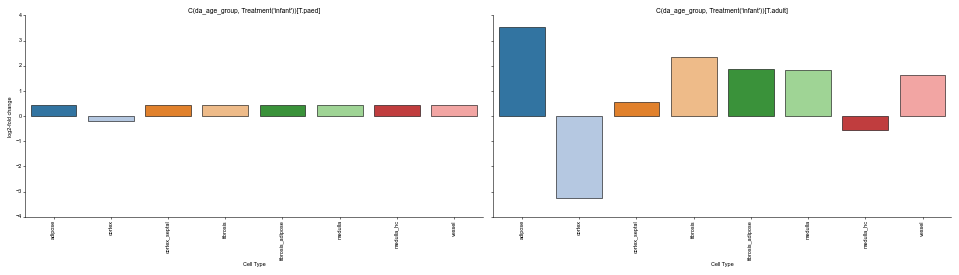

In [13]:
sccoda.plot_effects_barplot(coda)